In [1]:
%load_ext autoreload
%autoreload 2

# Gating + Adaptive Loss Weighting: A Negative Result

Stokes-Soret inverse case (mu, D, D_T). Pre-registered two-stage study comparing a gated backbone (ModifiedMLP) plus grad-norm adaptive loss weighting against a plain FNN with fixed weights.

The stage-A sweep is not re-runnable here: the PINN implementation it used has been retired. This notebook reads the 60 archived run JSONs under `result/gating_adaptive/runs/` and replays the criteria verdicts and figures. Criteria definitions and the ModifiedMLP live in `src/gating.py`.

In [2]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..") / "src"))

import gating
import json_util
import network
import plot_util

plot_util.apply_plot_style()

## Paths and Switches

In [3]:
RUN_SWEEP = False
FORCE_RERUN = False
RUN_STAGE_B = False

RESULT_DIR = Path("..") / "result" / "gating_adaptive"
FIGURE_DIR = RESULT_DIR / "figure"
RUNS_DIR = RESULT_DIR / "runs"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SCHEMA_EXPECTED = 1

LAYERS = (4, 64, 64, 64, 64, 6)
PARAMS = ("mu", "D", "DT")
SORET_TRUE = dict(gating.SORET_TRUE)
N_LEVELS = tuple(gating.N_LEVELS)
SEEDS_BY_N = {n: tuple(s) for n, s in gating.SEEDS_BY_N.items()}
PHASE3_REF = dict(gating.PHASE3_REF)
GRID = [(scheme, n) for scheme in ("hard", "soft") for n in N_LEVELS]


def load_runs():
    runs = {}
    for p in sorted(RUNS_DIR.glob("*.json")):
        with open(p, encoding="utf-8") as f:
            r = json.load(f, object_hook=json_util.json_deconvert)
        if r.get("schema") != SCHEMA_EXPECTED:
            raise RuntimeError(
                f"{p.name}: schema={r.get('schema')} != {SCHEMA_EXPECTED} -- stale result, "
                "rerun the sweep (FORCE_RERUN=True)")
        runs[r["id"]] = r
    if runs:
        budgets = {json.dumps(r["budget"], sort_keys=True) for r in runs.values()}
        if len(budgets) > 1:
            raise RuntimeError(f"Inconsistent budgets across runs: {budgets} -- "
                               "some results are stale, rerun the sweep (FORCE_RERUN=True)")
    return runs


def med_geo(runs, arm, scheme, n, seeds=None):
    seeds = SEEDS_BY_N[n] if seeds is None else seeds
    return float(np.median([gating.geo_err(runs[f"{arm}-{scheme}-n{n}-s{s}"]) for s in seeds]))


def med_param_err(runs, arm, scheme, n, param, seeds=None):
    seeds = SEEDS_BY_N[n] if seeds is None else seeds
    return float(np.median([runs[f"{arm}-{scheme}-n{n}-s{s}"]["rel_err_refit"][param]
                            for s in seeds]))


def arm_complete(runs, arm, scheme, n):
    return all(f"{arm}-{scheme}-n{n}-s{s}" in runs for s in SEEDS_BY_N[n])


print(f"RUN_SWEEP = {RUN_SWEEP}, FORCE_RERUN = {FORCE_RERUN}, RUN_STAGE_B = {RUN_STAGE_B}")
print(f"Results -> {RESULT_DIR.resolve()}")
n_a = len(gating.STAGE_A_IDS)
n_found = len(list(RUNS_DIR.glob("*.json"))) if RUNS_DIR.exists() else 0
print(f"Run JSONs found: {n_found} (stage A defines {n_a}; stage B adds up to {len(gating.JOBS) - n_a} more, condition-triggered)")
print(f"Collapse definition (pre-registered): mu_refit < {gating.COLLAPSE_MU} or D_refit < {gating.COLLAPSE_D}")

RUN_SWEEP = False, FORCE_RERUN = False, RUN_STAGE_B = False
Results -> D:\OneDrive\DocumentAll\Work\2-NIST\1-ALD_PINN\upload\result\gating_adaptive
Run JSONs found: 60 (stage A defines 60; stage B adds up to 60 more, condition-triggered)
Collapse definition (pre-registered): mu_refit < 0.008 or D_refit < 0.003


## 6.1 Capacity Gate

In [ ]:
# Use the new modular PINN to count baseline parameters
# layers = (4, 64, 64, 64, 64, 6)
# RBF(11**4) + ResNN(4*64 + 64*64*4 + 64*6) + Phys(64*6)
# We can just instantiate a temporary PINN with a dummy domain
import torch
from network import PINN

dummy_lo = [0, 0, 0, 0]
dummy_hi = [1, 1, 1, 1]
baseline_net = PINN(LAYERS, dummy_lo, dummy_hi)
n_fnn = sum(p.numel() for p in baseline_net.parameters() if p.requires_grad)

n_mm = sum(p.numel() for p in gating.ModifiedMLP(LAYERS).parameters() if p.requires_grad)
rel_diff_61 = abs(n_mm - n_fnn) / n_fnn
print(f"Baseline params: {n_fnn}   ModifiedMLP params: {n_mm}   rel diff: {rel_diff_61:.4f}  (threshold 0.10)")
print(f"criterion 6.1: {rel_diff_61 <= 0.10}")

## Stage A Sweep

In [5]:
if RUN_SWEEP:
    raise RuntimeError(
        "The stage-A sweep cannot be re-run from the mainline: its script and the PINN "
        "implementation it needs live only in ../archive/repo_2026_8_22/. "
        "Reuse the 60 run JSONs under result/gating_adaptive/runs/ instead.")
else:
    n = len(list(RUNS_DIR.glob("*.json"))) if RUNS_DIR.exists() else 0
    print(f"RUN_SWEEP = False -- reusing {n} existing run JSONs in {RUNS_DIR}")

RUN_SWEEP = False -- reusing 60 existing run JSONs in ..\result\gating_adaptive\runs


## 6.2 Baseline Reproduction Gate

off (hard, n=30) seeds 0-4:  per-seed geo err ['0.1429', '0.3781', '0.1266', '0.5246', '0.1011']
  median 0.1429  vs Phase 3 archived 0.1429  rel dev 0.000  (< 0.20)
off (soft, n=3000) seeds 0-4: per-seed geo err ['0.0151', '0.0266', '0.0380', '0.0090', '0.0278']
  median 0.0266  vs Phase 3 archived 0.0266  rel dev 0.001  (< 0.20)
collapsed seeds (0-4, hard n=30): [1, 3]  -> 2/5  (Phase 3: 2/5, seeds s1/s3)

criterion 6.2 (hard gate): True


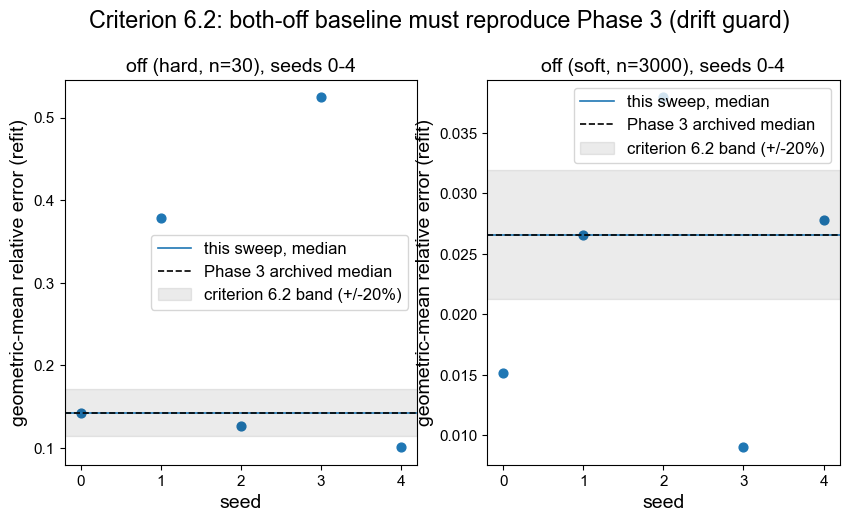

In [6]:
runs = load_runs()

geo_hard30 = {s: gating.geo_err(runs[f"off-hard-n30-s{s}"]) for s in range(5)}
geo_soft3000 = {s: gating.geo_err(runs[f"off-soft-n3000-s{s}"]) for s in range(5)}
med_hard30 = float(np.median(list(geo_hard30.values())))
med_soft3000 = float(np.median(list(geo_soft3000.values())))
dev_hard = abs(med_hard30 - PHASE3_REF["hard_n30_med_geo_err"]) / PHASE3_REF["hard_n30_med_geo_err"]
dev_soft = abs(med_soft3000 - PHASE3_REF["soft_n3000_med_geo_err"]) / PHASE3_REF["soft_n3000_med_geo_err"]
collapsed_04 = [s for s in range(5) if gating.is_collapsed(runs[f"off-hard-n30-s{s}"])]

print(f"off (hard, n=30) seeds 0-4:  per-seed geo err {[f'{v:.4f}' for v in geo_hard30.values()]}")
print(f"  median {med_hard30:.4f}  vs Phase 3 archived {PHASE3_REF['hard_n30_med_geo_err']}  "
      f"rel dev {dev_hard:.3f}  (< 0.20)")
print(f"off (soft, n=3000) seeds 0-4: per-seed geo err {[f'{v:.4f}' for v in geo_soft3000.values()]}")
print(f"  median {med_soft3000:.4f}  vs Phase 3 archived {PHASE3_REF['soft_n3000_med_geo_err']}  "
      f"rel dev {dev_soft:.3f}  (< 0.20)")
print(f"collapsed seeds (0-4, hard n=30): {collapsed_04}  -> {len(collapsed_04)}/5  "
      f"(Phase 3: {PHASE3_REF['hard_n30_collapsed_seeds_0_4']}/5, seeds s1/s3)")
ok_62 = (dev_hard < 0.20 and dev_soft < 0.20
         and len(collapsed_04) == PHASE3_REF["hard_n30_collapsed_seeds_0_4"])
print(f"\ncriterion 6.2 (hard gate): {ok_62}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (label, per_seed, ref) in zip(axes, [
        ("off (hard, n=30), seeds 0-4", geo_hard30, PHASE3_REF["hard_n30_med_geo_err"]),
        ("off (soft, n=3000), seeds 0-4", geo_soft3000, PHASE3_REF["soft_n3000_med_geo_err"])]):
    seeds = list(per_seed)
    ax.scatter(seeds, [per_seed[s] for s in seeds], s=40)
    ax.axhline(float(np.median(list(per_seed.values()))), color="tab:blue", ls="-", lw=1.2,
               label="this sweep, median")
    ax.axhline(ref, color="k", ls="--", lw=1.2, label="Phase 3 archived median")
    ax.axhspan(ref * 0.8, ref * 1.2, color="k", alpha=0.08, label="criterion 6.2 band (+/-20%)")
    ax.set_xlabel("seed")
    ax.set_ylabel("geometric-mean relative error (refit)")
    ax.set_title(label)
    ax.legend()
fig.suptitle("Criterion 6.2: both-off baseline must reproduce Phase 3 (drift guard)", y=1.02)
fig.savefig(FIGURE_DIR / "baseline_reproduction.png")
plt.show()

## 6.3 Dense Soft-BC Cell

(soft, n=3000)  med geo err: off 0.0266  on 0.0350  ratio 1.317  (<= 0.7)
                DT med err : off 0.0959  on 0.0972  (on <= 0.048)
criterion 6.3 (effect detected): False


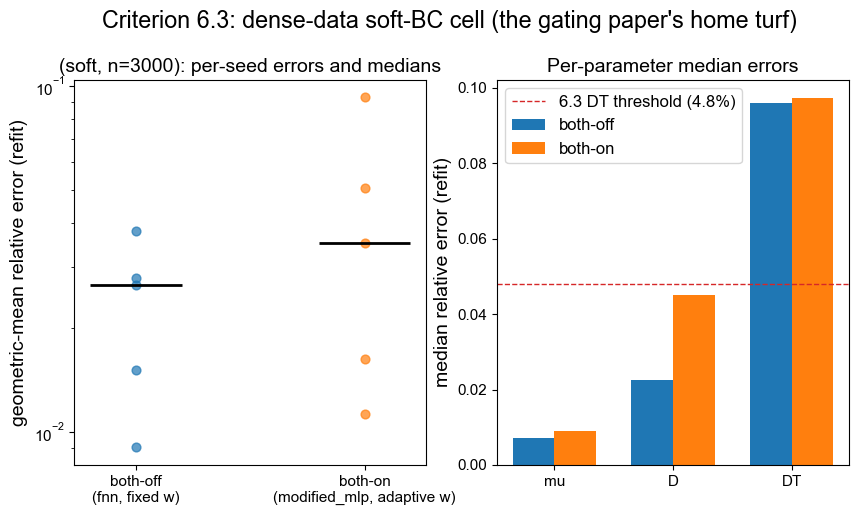

In [7]:
runs = load_runs()

off_med_63 = med_geo(runs, "off", "soft", 3000)
on_med_63 = med_geo(runs, "on", "soft", 3000)
ratio_63 = on_med_63 / off_med_63
dt_on_63 = med_param_err(runs, "on", "soft", 3000, "DT")
dt_off_63 = med_param_err(runs, "off", "soft", 3000, "DT")
ok_63 = ratio_63 <= 0.7 and dt_on_63 <= 0.048

print(f"(soft, n=3000)  med geo err: off {off_med_63:.4f}  on {on_med_63:.4f}  "
      f"ratio {ratio_63:.3f}  (<= 0.7)")
print(f"                DT med err : off {dt_off_63:.4f}  on {dt_on_63:.4f}  (on <= 0.048)")
print(f"criterion 6.3 (effect detected): {ok_63}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
ax = axes[0]
for i, arm in enumerate(("off", "on")):
    pts = [gating.geo_err(runs[f"{arm}-soft-n3000-s{s}"]) for s in SEEDS_BY_N[3000]]
    ax.scatter([i] * len(pts), pts, s=40, alpha=0.7)
    ax.hlines(float(np.median(pts)), i - 0.2, i + 0.2, color="k", lw=2)
ax.set_xticks([0, 1])
ax.set_xticklabels(["both-off\n(fnn, fixed w)", "both-on\n(modified_mlp, adaptive w)"])
ax.set_yscale("log")
ax.set_ylabel("geometric-mean relative error (refit)")
ax.set_title("(soft, n=3000): per-seed errors and medians")

ax = axes[1]
x = np.arange(len(PARAMS))
for i, arm in enumerate(("off", "on")):
    meds = [med_param_err(runs, arm, "soft", 3000, k) for k in PARAMS]
    ax.bar(x + (i - 0.5) * 0.35, meds, width=0.35, label=f"both-{arm}")
ax.axhline(0.048, color="tab:red", ls="--", lw=1, label="6.3 DT threshold (4.8%)")
ax.set_xticks(x)
ax.set_xticklabels(PARAMS)
ax.set_ylabel("median relative error (refit)")
ax.set_title("Per-parameter median errors")
ax.legend()
fig.suptitle("Criterion 6.3: dense-data soft-BC cell (the gating paper's home turf)", y=1.02)
fig.savefig(FIGURE_DIR / "criterion_63_soft_dense.png")
plt.show()

## 6.4 Sparse Hard-BC Collapse

collapse definition: mu_refit < 0.008 or D_refit < 0.003
both-off (hard, n=30): collapsed seeds [1, 3, 5]  -> 3/10
both-on (hard, n=30): collapsed seeds [0, 1, 2, 3, 5, 7]  -> 6/10
criterion 6.4 (effect detected): False  (both-on must be 0/10)


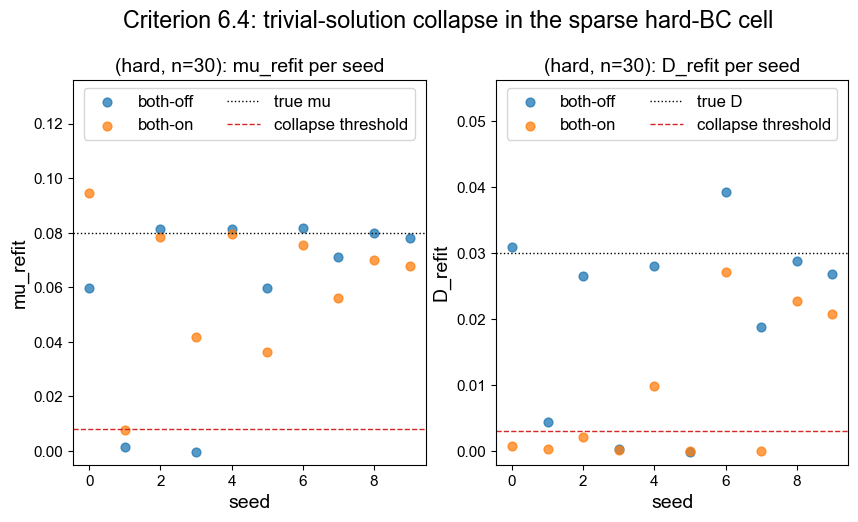

In [8]:
runs = load_runs()

collapse = {arm: [s for s in SEEDS_BY_N[30] if gating.is_collapsed(runs[f"{arm}-hard-n30-s{s}"])]
            for arm in ("off", "on")}
print(f"collapse definition: mu_refit < {gating.COLLAPSE_MU} or D_refit < {gating.COLLAPSE_D}")
for arm in ("off", "on"):
    print(f"both-{arm} (hard, n=30): collapsed seeds {collapse[arm]}  "
          f"-> {len(collapse[arm])}/{len(SEEDS_BY_N[30])}")
ok_64 = len(collapse["on"]) == 0
print(f"criterion 6.4 (effect detected): {ok_64}  (both-on must be 0/10)")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (param, thr) in zip(axes, [("mu", gating.COLLAPSE_MU), ("D", gating.COLLAPSE_D)]):
    for i, arm in enumerate(("off", "on")):
        vals = [runs[f"{arm}-hard-n30-s{s}"][f"{param}_refit"] for s in SEEDS_BY_N[30]]
        ax.scatter(SEEDS_BY_N[30], vals, s=40, alpha=0.75, label=f"both-{arm}")
    ax.axhline(SORET_TRUE[param], color="k", ls=":", lw=1, label=f"true {param}")
    ax.axhline(thr, color="tab:red", ls="--", lw=1, label="collapse threshold")
    ax.set_xlabel("seed")
    ax.set_ylabel(f"{param}_refit")
    ax.set_title(f"(hard, n=30): {param}_refit per seed")
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + 0.35 * (hi - lo))
    ax.legend(loc="upper center", ncol=2)
fig.suptitle("Criterion 6.4: trivial-solution collapse in the sparse hard-BC cell", y=1.02)
fig.savefig(FIGURE_DIR / "criterion_64_collapse.png")
plt.show()

## 6.5 Direction Robustness

     n   Phase3 (fnn, archived)   off (this sweep)    on (this sweep)
  3000                    0.263              0.263              9.800
    30                    1.547              1.493              1.066

direction under both-on vs Phase 3: n=3000: FLIPPED, n=30: SAME
criterion 6.5: reported  -- WARNING: direction flipped, Phase 3 guidance is backbone-dependent


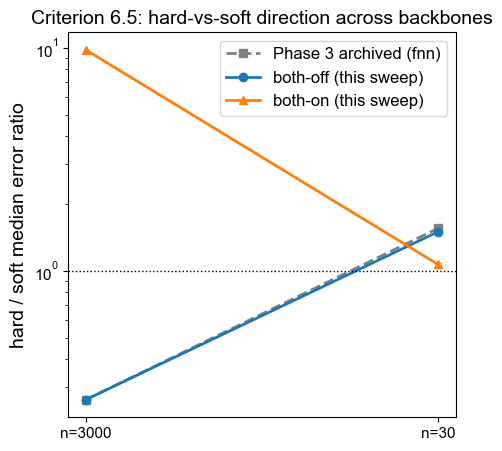

In [9]:
runs = load_runs()

PHASE3_RATIOS = {3000: 0.263, 30: 1.547}
ratios = {}
for arm in ("off", "on"):
    ratios[arm] = {n: med_geo(runs, arm, "hard", n) / med_geo(runs, arm, "soft", n)
                   for n in N_LEVELS}

print(f"{'n':>6s} {'Phase3 (fnn, archived)':>24s} {'off (this sweep)':>18s} {'on (this sweep)':>18s}")
for n in N_LEVELS:
    print(f"{n:6d} {PHASE3_RATIOS[n]:24.3f} {ratios['off'][n]:18.3f} {ratios['on'][n]:18.3f}")

dir_same = {n: (ratios["on"][n] < 1) == (PHASE3_RATIOS[n] < 1) for n in N_LEVELS}
flipped = [n for n in N_LEVELS if not dir_same[n]]
print(f"\ndirection under both-on vs Phase 3: "
      + ", ".join(f"n={n}: {'SAME' if dir_same[n] else 'FLIPPED'}" for n in N_LEVELS))
print("criterion 6.5: reported"
      + ("  -- WARNING: direction flipped, Phase 3 guidance is backbone-dependent"
         if flipped else "  -- Phase 3 direction robust under both-on"))

fig, ax = plt.subplots(figsize=(5, 5))
xs = np.arange(len(N_LEVELS))
ax.plot(xs, [PHASE3_RATIOS[n] for n in N_LEVELS], marker="s", ls="--", color="gray",
        label="Phase 3 archived (fnn)")
ax.plot(xs, [ratios["off"][n] for n in N_LEVELS], marker="o", label="both-off (this sweep)")
ax.plot(xs, [ratios["on"][n] for n in N_LEVELS], marker="^", label="both-on (this sweep)")
ax.axhline(1.0, color="k", lw=1, ls=":")
ax.set_xticks(xs)
ax.set_xticklabels([f"n={n}" for n in N_LEVELS])
ax.set_yscale("log")
ax.set_ylabel("hard / soft median error ratio")
ax.set_title("Criterion 6.5: hard-vs-soft direction across backbones")
ax.legend()
fig.savefig(FIGURE_DIR / "criterion_65_direction.png")
plt.show()

## Stage B Attribution Arms

In [10]:
triggers = gating.evaluate_triggers(gating.load_stage_a_runs(RUNS_DIR))
print("mechanical trigger evaluation (from stage-A JSONs):")
print(f"  6.2 gate     : pass={triggers['gate_6_2']['pass']}  "
      f"rel dev hard/soft = {triggers['gate_6_2']['rel_dev_hard_n30']:.3f} / "
      f"{triggers['gate_6_2']['rel_dev_soft_n3000']:.3f}  "
      f"collapsed(0-4) = {triggers['gate_6_2']['collapsed_seeds_0_4']}/5")
print(f"  6.3 trigger  : {triggers['trigger_6_3']['triggered']}  "
      f"ratio = {triggers['trigger_6_3']['ratio']:.3f} (<= 0.7)  "
      f"on DT med = {triggers['trigger_6_3']['on_DT_med_err']:.4f} (<= 0.048)")
print(f"  6.4 trigger  : {triggers['trigger_6_4']['triggered']}  "
      f"on collapsed = {triggers['trigger_6_4']['on_collapsed']}/10  "
      f"(off: {triggers['trigger_6_4']['off_collapsed']}/10)")

any_triggered = triggers["trigger_6_3"]["triggered"] or triggers["trigger_6_4"]["triggered"]
if RUN_STAGE_B and triggers["gate_6_2"]["pass"] and any_triggered:
    raise RuntimeError(
        "The stage-B sweep cannot be re-run from the mainline: its script and the PINN "
        "implementation it needs live only in ../archive/repo_2026_8_22/.")
elif not any_triggered:
    print("\nstage B NOT TRIGGERED (neither 6.3 nor 6.4 detected an effect) -- "
          "pre-registered legitimate outcome, criterion 6.6 records 'not triggered'.")
elif not triggers["gate_6_2"]["pass"]:
    print("\nstage B REFUSED: criterion 6.2 failed -- all Phase 6 readings are void per the "
          "pre-registered clause.")
else:
    print("\nRUN_STAGE_B = False -- reusing existing stage-B JSONs (if any).")

mechanical trigger evaluation (from stage-A JSONs):
  6.2 gate     : pass=True  rel dev hard/soft = 0.000 / 0.001  collapsed(0-4) = 2/5
  6.3 trigger  : False  ratio = 1.317 (<= 0.7)  on DT med = 0.0972 (<= 0.048)
  6.4 trigger  : False  on collapsed = 6/10  (off: 3/10)

stage B NOT TRIGGERED (neither 6.3 nor 6.4 detected an effect) -- pre-registered legitimate outcome, criterion 6.6 records 'not triggered'.


## 6.6 Attribution

In [11]:
runs = load_runs()
triggers = gating.evaluate_triggers(gating.load_stage_a_runs(RUNS_DIR))

attribution = {}
cells_66 = []
if triggers["trigger_6_3"]["triggered"]:
    cells_66.append(("soft", 3000, "error"))
if triggers["trigger_6_4"]["triggered"]:
    cells_66.append(("hard", 30, "collapse"))

if not cells_66:
    print("criterion 6.6: NOT TRIGGERED (recorded; not a failure)")
else:
    for scheme, n, kind in cells_66:
        missing = [a for a in ("gate", "adw") if not arm_complete(runs, a, scheme, n)]
        if missing:
            print(f"({scheme}, n={n}): stage-B arms missing {missing} -- run stage B first")
            continue
        if kind == "error":
            base = med_geo(runs, "off", scheme, n)
            eff = {arm: base - med_geo(runs, arm, scheme, n) for arm in ("on", "gate", "adw")}
            metric = "median geo-err reduction vs both-off"
        else:
            base = sum(gating.is_collapsed(runs[f"off-{scheme}-n{n}-s{s}"]) for s in SEEDS_BY_N[n])
            eff = {arm: base - sum(gating.is_collapsed(runs[f"{arm}-{scheme}-n{n}-s{s}"])
                                   for s in SEEDS_BY_N[n])
                   for arm in ("on", "gate", "adw")}
            metric = "collapsed-seed reduction vs both-off"
        main_effect = any(eff[a] >= 0.5 * eff["on"] for a in ("gate", "adw")) if eff["on"] > 0 else None
        attribution[f"{scheme}-n{n}"] = {"metric": metric, "effects": eff,
                                         "single_factor_is_main_effect": main_effect}
        arm_label = {"on": "both-on", "gate": "gating-only", "adw": "adaptive-only"}
        print(f"({scheme}, n={n})  [{metric}]")
        for arm in ("on", "gate", "adw"):
            print(f"  {arm_label[arm]:>14s}: effect = {eff[arm]:+.4f}")
        print(f"  -> single-factor main effect: {main_effect} "
              f"(True = NB4 interaction NOT reproduced)")

    if attribution:
        fig, axes = plt.subplots(1, len(attribution), figsize=(5 * len(attribution), 5),
                                 squeeze=False)
        for ax, (cell_name, a) in zip(axes[0], attribution.items()):
            arms = ["on", "gate", "adw"]
            ax.bar(np.arange(3), [a["effects"][x] for x in arms])
            ax.axhline(0.5 * a["effects"]["on"], color="tab:red", ls="--", lw=1,
                       label="half of both-on effect")
            ax.set_xticks(np.arange(3))
            ax.set_xticklabels(["both-on", "gating-only", "adaptive-only"])
            ax.set_ylabel(a["metric"])
            ax.set_title(f"Criterion 6.6: attribution in ({cell_name})")
            ax.legend()
        fig.savefig(FIGURE_DIR / "criterion_66_attribution.png")
        plt.show()

criterion 6.6: NOT TRIGGERED (recorded; not a failure)


## 6.7 Adaptive Weight Behavior

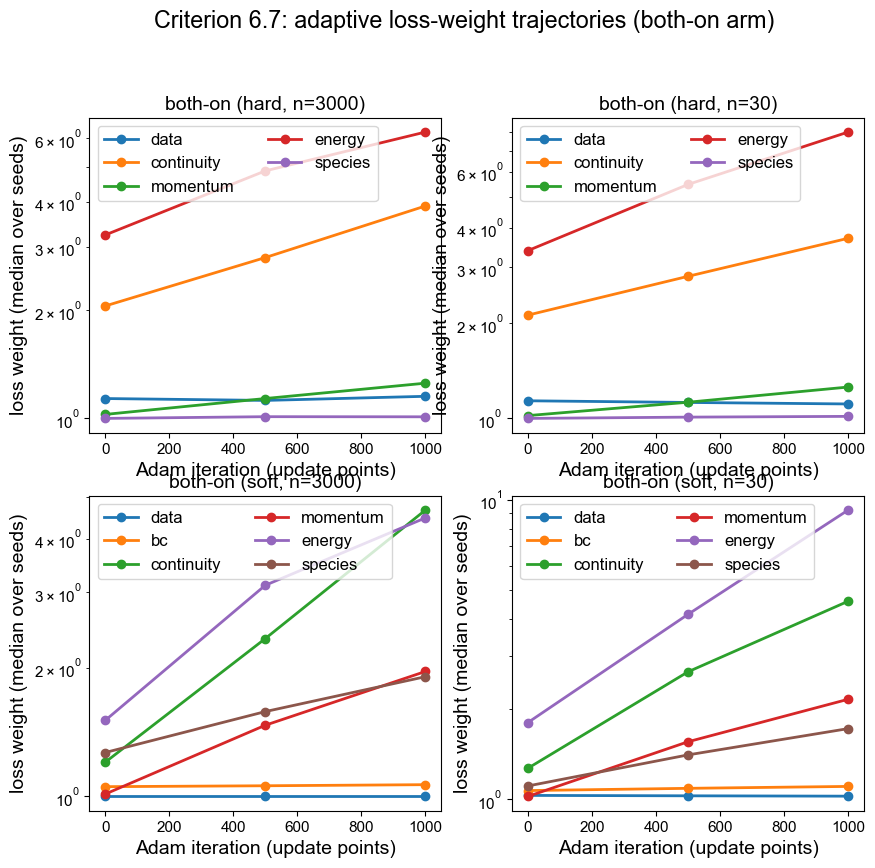

          cell  max resid w (final)  data w (final)  resid/data
    hard-n3000                 6.24            1.15         5.1
      hard-n30                 8.02            1.11        7.29
    soft-n3000                  4.7               1         4.7
      soft-n30                 10.1            1.03         9.6

mechanical reading, (hard, n=30): median final max-residual/data weight ratio = 7.29
  > 1  -> residual terms lifted ABOVE the data term (Phase-4-like direction: data suppressed)
  < 1  -> data term lifted ABOVE residual terms (rescue-the-collapse direction)
  Phase 4 reference magnitude: residual weight lifted to ~1.5e3 at iter 0


In [12]:
runs = load_runs()

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
readings_67 = {}
for ax, (scheme, n) in zip(axes.flat, GRID):
    seeds = SEEDS_BY_N[n]
    trajs = [runs[f"on-{scheme}-n{n}-s{s}"]["history"]["loss_weights"] for s in seeds]
    term_names = [k for k in trajs[0][0] if k != "iteration"]
    iters = [e["iteration"] for e in trajs[0]]
    for name in term_names:
        med_traj = [float(np.median([t[i][name] for t in trajs])) for i in range(len(iters))]
        ax.plot(iters, med_traj, marker="o", label=name)
    ax.set_yscale("log")
    ax.set_xlabel("Adam iteration (update points)")
    ax.set_ylabel("loss weight (median over seeds)")
    ax.set_title(f"both-on ({scheme}, n={n})")
    ax.legend(ncol=2)

    resid_terms = [k for k in term_names if k not in ("data", "bc")]
    finals = []
    for t in trajs:
        last = t[-1]
        finals.append(max(last[k] for k in resid_terms) / last["data"])
    readings_67[f"{scheme}-n{n}"] = {
        "median_final_max_residual_weight": float(np.median(
            [max(t[-1][k] for k in resid_terms) for t in trajs])),
        "median_final_data_weight": float(np.median([t[-1]["data"] for t in trajs])),
        "median_final_residual_over_data": float(np.median(finals)),
    }
fig.suptitle("Criterion 6.7: adaptive loss-weight trajectories (both-on arm)", y=1.0)
fig.savefig(FIGURE_DIR / "criterion_67_weight_trajectories.png")
plt.show()

print(f"{'cell':>14s} {'max resid w (final)':>20s} {'data w (final)':>15s} {'resid/data':>11s}")
for cell_name, v in readings_67.items():
    print(f"{cell_name:>14s} {v['median_final_max_residual_weight']:20.3g} "
          f"{v['median_final_data_weight']:15.3g} {v['median_final_residual_over_data']:11.3g}")

r_hard30 = readings_67["hard-n30"]["median_final_residual_over_data"]
print(f"\nmechanical reading, (hard, n=30): median final max-residual/data weight ratio = {r_hard30:.3g}")
print("  > 1  -> residual terms lifted ABOVE the data term (Phase-4-like direction: data suppressed)")
print("  < 1  -> data term lifted ABOVE residual terms (rescue-the-collapse direction)")
print(f"  Phase 4 reference magnitude: residual weight lifted to ~1.5e3 at iter 0")

## 6.8 Cost Accounting

wall-clock protocol violations (skipped / busy pre / busy post): ['on-hard-n30-s6']
runs with idle context holders (recorded, not contention): 32

          cell  median on/off   per-seed ratios
    hard-n3000          1.784   1.74 1.77 1.79 1.78 1.81
      hard-n30          1.779   1.79 1.78 1.79 1.78 1.77 1.79 2.68 1.71 1.43 1.76
    soft-n3000          2.081   2.10 2.07 2.04 2.10 2.08
      soft-n30          2.090   2.09 2.10 2.07 2.03 2.08 2.09 2.08 2.11 2.12 2.10

suspect wall clocks (snapshot flags + sibling-comparison > 1.25x config median):
  off-hard-n30-s7: outlier 1.41x
  off-hard-n30-s8: outlier 1.55x
  off-hard-n3000-s4: outlier 1.66x
  on-hard-n30-s6: snapshot flag+outlier 1.49x
  on-hard-n30-s7: outlier 1.34x
  on-hard-n3000-s4: outlier 1.70x

criterion 6.8: overall median both-on/both-off wall-clock ratio = 2.034 (all 30 pairs)
               excluding 4 suspect pair(s): 2.056 (26 pairs)
total wall clock over all 60 runs: 3.33 h

stage-B cost decomposition: stage B not 

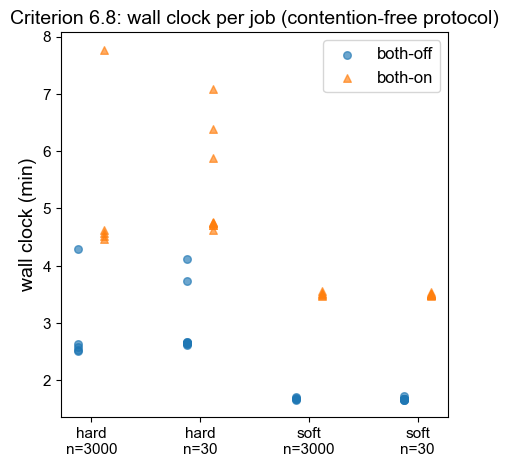

In [13]:
runs = load_runs()

protocol_bad = [i for i, r in runs.items()
                if r["gpu_check"].get("skipped") or r["gpu_check"].get("busy_other")
                or (r.get("gpu_check_post") or {}).get("busy_other")]
idle_holders = [i for i, r in runs.items() if r["gpu_check"].get("idle_context_holders")]
print(f"wall-clock protocol violations (skipped / busy pre / busy post): "
      f"{protocol_bad if protocol_bad else 'none'}")
print(f"runs with idle context holders (recorded, not contention): {len(idle_holders)}")

pair_ratio = {}
for scheme, n in GRID:
    for s in SEEDS_BY_N[n]:
        pair_ratio[(scheme, n, s)] = (runs[f"on-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                                      / runs[f"off-{scheme}-n{n}-s{s}"]["wall_clock_s"])
overall_med = float(np.median(list(pair_ratio.values())))
print(f"\n{'cell':>14s} {'median on/off':>14s}   per-seed ratios")
for scheme, n in GRID:
    level = [pair_ratio[(scheme, n, s)] for s in SEEDS_BY_N[n]]
    print(f"{scheme + '-n' + str(n):>14s} {float(np.median(level)):14.3f}   "
          + " ".join(f"{v:.2f}" for v in level))

wall_outliers = {}
for scheme, n in GRID:
    for arm in ("off", "on"):
        walls = {s: runs[f"{arm}-{scheme}-n{n}-s{s}"]["wall_clock_s"] for s in SEEDS_BY_N[n]}
        med_w = float(np.median(list(walls.values())))
        for s, w in walls.items():
            if w > 1.25 * med_w:
                wall_outliers[f"{arm}-{scheme}-n{n}-s{s}"] = {
                    "wall_s": float(w), "config_median_s": med_w, "ratio": float(w / med_w)}
suspect_ids = sorted(set(protocol_bad) | set(wall_outliers))
suspect_pairs = {key for key in pair_ratio
                 if any(f"{arm}-{key[0]}-n{key[1]}-s{key[2]}" in suspect_ids for arm in ("off", "on"))}
clean_ratios = [v for k, v in pair_ratio.items() if k not in suspect_pairs]
print(f"\nsuspect wall clocks (snapshot flags + sibling-comparison > 1.25x config median):")
for i in suspect_ids:
    src = "snapshot flag" if i in protocol_bad else ""
    if i in wall_outliers:
        src += ("+" if src else "") + f"outlier {wall_outliers[i]['ratio']:.2f}x"
    print(f"  {i}: {src}")
if not suspect_ids:
    print("  none")
print(f"\ncriterion 6.8: overall median both-on/both-off wall-clock ratio = {overall_med:.3f} "
      f"(all {len(pair_ratio)} pairs)")
print(f"               excluding {len(suspect_pairs)} suspect pair(s): "
      f"{float(np.median(clean_ratios)):.3f} ({len(clean_ratios)} pairs)")
total_wall_h = sum(r["wall_clock_s"] for r in runs.values()) / 3600.0
print(f"total wall clock over all {len(runs)} runs: {total_wall_h:.2f} h")

decomp = {}
for scheme, n in GRID:
    if all(arm_complete(runs, a, scheme, n) for a in ("gate", "adw")):
        decomp[f"{scheme}-n{n}"] = {
            "gate_over_off": float(np.median([runs[f"gate-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                                              / runs[f"off-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                                              for s in SEEDS_BY_N[n]])),
            "adw_over_off": float(np.median([runs[f"adw-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                                             / runs[f"off-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                                             for s in SEEDS_BY_N[n]])),
        }
if decomp:
    print("\nstage-B cost decomposition (median ratios vs both-off):")
    for cell_name, d in decomp.items():
        print(f"  {cell_name}: gating-only {d['gate_over_off']:.3f}  "
              f"adaptive-only {d['adw_over_off']:.3f}")
else:
    print("\nstage-B cost decomposition: stage B not run (not triggered or not yet run)")

fig, ax = plt.subplots(figsize=(5, 5))
x_pos = {(scheme, n): i for i, (scheme, n) in enumerate(GRID)}
for arm, marker in (("off", "o"), ("on", "^")):
    xs, ys = [], []
    for scheme, n in GRID:
        for s in SEEDS_BY_N[n]:
            xs.append(x_pos[(scheme, n)] + (0.12 if arm == "on" else -0.12))
            ys.append(runs[f"{arm}-{scheme}-n{n}-s{s}"]["wall_clock_s"] / 60.0)
    ax.scatter(xs, ys, s=30, alpha=0.65, marker=marker, label=f"both-{arm}")
ax.set_xticks(list(x_pos.values()))
ax.set_xticklabels([f"{scheme}\nn={n}" for scheme, n in GRID])
ax.set_ylabel("wall clock (min)")
ax.set_title("Criterion 6.8: wall clock per job (contention-free protocol)")
ax.legend()
fig.savefig(FIGURE_DIR / "wall_clock.png")
plt.show()

## Verdict Summary

In [14]:
runs = load_runs()
verdict = {}

n_fnn = sum(p.numel() for p in network.FNN(LAYERS).parameters() if p.requires_grad)
n_mm = sum(p.numel() for p in gating.ModifiedMLP(LAYERS).parameters() if p.requires_grad)
rd = abs(n_mm - n_fnn) / n_fnn
verdict["6.1"] = {"n_params_fnn": int(n_fnn), "n_params_modified_mlp": int(n_mm),
                  "rel_diff": float(rd), "threshold": 0.10,
                  "pass": bool(rd <= 0.10)}

triggers = gating.evaluate_triggers(gating.load_stage_a_runs(RUNS_DIR))
verdict["6.2"] = dict(triggers["gate_6_2"])

verdict["6.3"] = {k: v for k, v in triggers["trigger_6_3"].items()}
verdict["6.3"]["pass"] = verdict["6.3"].pop("triggered")
verdict["6.4"] = {k: v for k, v in triggers["trigger_6_4"].items()}
verdict["6.4"]["pass"] = verdict["6.4"].pop("triggered")

PHASE3_RATIOS = {3000: 0.263, 30: 1.547}
ratios_on = {n: med_geo(runs, "on", "hard", n) / med_geo(runs, "on", "soft", n) for n in N_LEVELS}
ratios_off = {n: med_geo(runs, "off", "hard", n) / med_geo(runs, "off", "soft", n) for n in N_LEVELS}
flipped = [n for n in N_LEVELS if (ratios_on[n] < 1) != (PHASE3_RATIOS[n] < 1)]
verdict["6.5"] = {"hard_over_soft_on": {str(n): ratios_on[n] for n in N_LEVELS},
                  "hard_over_soft_off": {str(n): ratios_off[n] for n in N_LEVELS},
                  "phase3_archived": {str(n): PHASE3_RATIOS[n] for n in N_LEVELS},
                  "direction_flipped_at": [int(n) for n in flipped],
                  "note": "flip => Phase 3 guidance is backbone-dependent (acceptance updates decisions.md)",
                  "pass": True}

any_trig = verdict["6.3"]["pass"] or verdict["6.4"]["pass"]
attribution = {}
if any_trig:
    cells_66 = ([("soft", 3000, "error")] if verdict["6.3"]["pass"] else []) + \
               ([("hard", 30, "collapse")] if verdict["6.4"]["pass"] else [])
    for scheme, n, kind in cells_66:
        if not all(arm_complete(runs, a, scheme, n) for a in ("gate", "adw")):
            attribution[f"{scheme}-n{n}"] = {"status": "stage-B arms missing"}
            continue
        if kind == "error":
            base = med_geo(runs, "off", scheme, n)
            eff = {arm: base - med_geo(runs, arm, scheme, n) for arm in ("on", "gate", "adw")}
        else:
            base = sum(gating.is_collapsed(runs[f"off-{scheme}-n{n}-s{s}"]) for s in SEEDS_BY_N[n])
            eff = {arm: base - sum(gating.is_collapsed(runs[f"{arm}-{scheme}-n{n}-s{s}"])
                                   for s in SEEDS_BY_N[n]) for arm in ("on", "gate", "adw")}
        main_eff = any(eff[a] >= 0.5 * eff["on"] for a in ("gate", "adw")) if eff["on"] > 0 else None
        attribution[f"{scheme}-n{n}"] = {"metric": kind, "effects": {k: float(v) for k, v in eff.items()},
                                         "single_factor_is_main_effect": main_eff}
    complete = all(a.get("status") != "stage-B arms missing" for a in attribution.values())
    verdict["6.6"] = {"attribution": attribution, "pass": bool(complete)}
else:
    verdict["6.6"] = {"status": "not_triggered (recorded per pre-registration; not a failure)",
                      "pass": True}

readings = {}
for scheme, n in GRID:
    trajs = [runs[f"on-{scheme}-n{n}-s{s}"]["history"]["loss_weights"] for s in SEEDS_BY_N[n]]
    resid = [k for k in trajs[0][0] if k not in ("iteration", "data", "bc")]
    readings[f"{scheme}-n{n}"] = {
        "median_final_max_residual_weight": float(np.median(
            [max(t[-1][k] for k in resid) for t in trajs])),
        "median_final_data_weight": float(np.median([t[-1]["data"] for t in trajs])),
        "median_final_residual_over_data": float(np.median(
            [max(t[-1][k] for k in resid) / t[-1]["data"] for t in trajs])),
    }
r_h30 = readings["hard-n30"]["median_final_residual_over_data"]
verdict["6.7"] = {"final_weight_readings": readings,
                  "phase4_pattern_question": "did grad-norm lift residual weights above the data "
                                             "term (Phase-4-like suppression) in (hard, n=30)?",
                  "residual_over_data_hard_n30": float(r_h30),
                  "mechanical_reading": ("data term SUPPRESSED (Phase-4-like)" if r_h30 > 1
                                         else "data term LIFTED (rescue direction)"),
                  "pass": True}

pair_ratio_68 = {(scheme, n, s): runs[f"on-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                 / runs[f"off-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                 for scheme, n in GRID for s in SEEDS_BY_N[n]}
pair_ratios = list(pair_ratio_68.values())
protocol_bad = [i for i, r in runs.items()
                if r["gpu_check"].get("skipped") or r["gpu_check"].get("busy_other")
                or (r.get("gpu_check_post") or {}).get("busy_other")]
wall_outliers = {}
for scheme, n in GRID:
    for arm in ("off", "on"):
        walls = {s: runs[f"{arm}-{scheme}-n{n}-s{s}"]["wall_clock_s"] for s in SEEDS_BY_N[n]}
        med_w = float(np.median(list(walls.values())))
        for s, w in walls.items():
            if w > 1.25 * med_w:
                wall_outliers[f"{arm}-{scheme}-n{n}-s{s}"] = {
                    "wall_s": float(w), "config_median_s": med_w, "ratio": float(w / med_w)}
suspect_ids = sorted(set(protocol_bad) | set(wall_outliers))
suspect_pairs = {key for key in pair_ratio_68
                 if any(f"{arm}-{key[0]}-n{key[1]}-s{key[2]}" in suspect_ids for arm in ("off", "on"))}
clean_ratios = [v for k, v in pair_ratio_68.items() if k not in suspect_pairs]
decomp = {}
for scheme, n in GRID:
    if all(arm_complete(runs, a, scheme, n) for a in ("gate", "adw")):
        decomp[f"{scheme}-n{n}"] = {
            "gate_over_off": float(np.median([runs[f"gate-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                                              / runs[f"off-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                                              for s in SEEDS_BY_N[n]])),
            "adw_over_off": float(np.median([runs[f"adw-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                                             / runs[f"off-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                                             for s in SEEDS_BY_N[n]])),
        }
verdict["6.8"] = {"median_on_over_off_wall_clock": float(np.median(pair_ratios)),
                  "median_excluding_suspect_pairs": float(np.median(clean_ratios)),
                  "n_pairs": len(pair_ratios), "n_suspect_pairs": len(suspect_pairs),
                  "per_cell_median": {f"{scheme}-n{n}": float(np.median(
                      [runs[f"on-{scheme}-n{n}-s{s}"]["wall_clock_s"]
                       / runs[f"off-{scheme}-n{n}-s{s}"]["wall_clock_s"] for s in SEEDS_BY_N[n]]))
                      for scheme, n in GRID},
                  "stage_b_decomposition": decomp if decomp else "stage B not run",
                  "protocol_violations": protocol_bad,
                  "suspect_wall_clocks": {i: wall_outliers.get(i, "snapshot flag")
                                          for i in suspect_ids},
                  "suspect_rule": "snapshot flags OR wall > 1.25x same-config median "
                                  "(diagnostic report, not a criterion; params kept per Phase 3 "
                                  "precedent, suspect wall clocks must not be quoted alone)",
                  "total_wall_clock_h": float(sum(r["wall_clock_s"] for r in runs.values()) / 3600.0),
                  "n_runs": len(runs),
                  "pass": True}

verdict["_meta"] = {"budget": next(iter(runs.values()))["budget"], "n_runs": len(runs),
                    "arms": {a: {k: v for k, v in spec.items()} for a, spec in gating.ARMS.items()},
                    "collapse_def": f"mu_refit < {gating.COLLAPSE_MU} or D_refit < {gating.COLLAPSE_D}",
                    "error_metric": "geometric mean of refit relative errors (mu/D/DT), "
                                    "median over the cell's seeds"}

with open(RESULT_DIR / "criteria_verdict.json", "w", encoding="utf-8") as f:
    json.dump(verdict, f, ensure_ascii=False, indent=2)

print(f"{'criterion':>9s}  {'result':6s}  key numbers")
for cid in ("6.1", "6.2", "6.3", "6.4", "6.5", "6.6", "6.7", "6.8"):
    v = verdict[cid]
    status = "PASS" if v["pass"] else "FAIL"
    nums = {k: val for k, val in v.items() if k not in ("pass",)}
    print(f"{cid:>9s}  {status:6s}  {json.dumps(nums, default=str)[:170]}")
print(f"\nverdict written to {RESULT_DIR / 'criteria_verdict.json'}")
print("NOTE: 6.3/6.4 'FAIL' is a pre-registered legitimate negative outcome "
      "(fnn default validated), NOT an implementation failure; acceptance decides.")

criterion  result  key numbers
      6.1  PASS    {"n_params_fnn": 13190, "n_params_modified_mlp": 13830, "rel_diff": 0.04852160727824109, "threshold": 0.1}
      6.2  PASS    {"off_hard_n30_med_geo_err_seeds_0_4": 0.14289715178371742, "off_soft_n3000_med_geo_err_seeds_0_4": 0.026580351821939734, "rel_dev_hard_n30": 1.9931534517669156e-05, "rel
      6.3  FAIL    {"cell": ["soft", 3000], "on_med_geo_err": 0.035000998113411924, "off_med_geo_err": 0.026580351821939734, "ratio": 1.3167996551694132, "ratio_max": 0.7, "on_DT_med_err": 
      6.4  FAIL    {"cell": ["hard", 30], "on_collapsed": 6, "off_collapsed": 3, "n_seeds": 10, "collapse_def": "mu_refit < 0.008 or D_refit < 0.003"}
      6.5  PASS    {"hard_over_soft_on": {"3000": 9.800328598332666, "30": 1.0664879469018287}, "hard_over_soft_off": {"3000": 0.26314752812554404, "30": 1.492533463966162}, "phase3_archive
      6.6  PASS    {"status": "not_triggered (recorded per pre-registration; not a failure)"}
      6.7  PASS    {"final_w